## 1. Setup and load the data

I will start with the libraries needed for cleaning, charts and regression. Rather than importing every possible algorithm, I will add only what this investigation uses.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

In [ ]:
# Look for the CSV first; Colab often renames repeated downloads, e.g. (1)(3).
csv_files = sorted(Path(".").glob("ai_student_impact_dataset*.csv"))

if not csv_files:
    try:
        from google.colab import files
        print("Upload the AI Impact on Students CSV file:")
        uploaded = files.upload()
        csv_files = [Path(name) for name in uploaded if name.lower().endswith(".csv")]
    except ImportError:
        pass

if not csv_files:
    raise FileNotFoundError("Please upload the AI Impact on Students CSV and run this cell again.")

csv_path = csv_files[0]
df = pd.read_csv(csv_path)
print(f"Loaded: {csv_path.name}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Loaded: ai_student_impact_dataset (1).csv
Shape: 50,000 rows × 16 columns


,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


## 2. Understand what is in the dataset

Before choosing a model, I want to know what each row represents, which columns are numerical or categorical, and whether any records need attention. The dataset describes individual **simulated student profiles**.

In [ ]:
# A first check: data types, missing entries and repeated records.
print("Column types:")
display(pd.DataFrame({"type": df.dtypes.astype(str), "missing": df.isna().sum()}))

print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Duplicate student IDs: {df['Student_ID'].duplicated().sum():,}")

# A short summary of the measures directly related to the research question.
key_columns = [
    "Pre_Semester_GPA", "Post_Semester_GPA", "Weekly_GenAI_Hours",
    "Traditional_Study_Hours", "Perceived_AI_Dependency", "Skill_Retention_Score"
]
display(df[key_columns].describe().round(2))

Column types:


,type,missing
Student_ID,int64,0
Major_Category,object,0
Year_of_Study,object,0
Pre_Semester_GPA,float64,0
Weekly_GenAI_Hours,float64,0
Primary_Use_Case,object,0
Prompt_Engineering_Skill,object,0
Tool_Diversity,int64,0
Paid_Subscription,bool,0
Traditional_Study_Hours,float64,0


Duplicate rows: 0
Duplicate student IDs: 0


,Pre_Semester_GPA,Post_Semester_GPA,Weekly_GenAI_Hours,Traditional_Study_Hours,Perceived_AI_Dependency,Skill_Retention_Score
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,3.15,3.35,8.43,11.21,3.51,75.80
std,0.48,0.50,8.27,5.16,1.82,13.28
min,1.18,1.00,0.00,1.00,1.00,10.78
25%,2.83,3.02,2.39,7.56,2.00,66.82
50%,3.21,3.42,5.80,11.18,3.00,76.00
75%,3.52,3.75,11.72,14.71,5.00,85.19
max,4.00,4.00,40.00,35.86,10.00,100.00


In [ ]:
# Check plausible ranges rather than assuming every number is valid.
checks = {
    "GPA before semester (0–4)": df["Pre_Semester_GPA"].dropna().between(0, 4).all(),
    "GPA after semester (0–4)": df["Post_Semester_GPA"].dropna().between(0, 4).all(),
    "GenAI hours are non-negative": (df["Weekly_GenAI_Hours"].dropna() >= 0).all(),
    "Traditional study hours are non-negative": (df["Traditional_Study_Hours"].dropna() >= 0).all(),
    "Skill retention is 0–100": df["Skill_Retention_Score"].dropna().between(0, 100).all()
}
display(pd.DataFrame({"check": checks.keys(), "passed": checks.values()}))

if not all(checks.values()):
    raise ValueError("One or more range checks failed. Inspect those records before modelling.")

,check,passed
0,GPA before semester (0–4),True
1,GPA after semester (0–4),True
2,GenAI hours are non-negative,True
3,Traditional study hours are non-negative,True
4,Skill retention is 0–100,True


## 3. Cleaning and feature engineering

The initial checks show whether cleaning is necessary. I will **not delete or replace records without a reason**. The model pipeline later handles any missing input values using training data only.

My main outcome is **GPA change** rather than GPA after the semester alone. This is useful because students begin with different GPA levels. I will also create an **AI study share** to describe how AI hours compare with the combined AI and traditional study hours. It is an exploratory indicator, not a literal measure of learning quality.

In [ ]:
data = df.copy()

# Remove exact duplicate records only if any are found.
rows_before = len(data)
data = data.drop_duplicates().copy()
print(f"Exact duplicates removed: {rows_before - len(data)}")

# The subscription column is already Boolean; convert it to 0/1 for modelling.
data["Paid_Subscription"] = data["Paid_Subscription"].map({True: 1, False: 0, "Yes": 1, "No": 0})

# Two derived variables that directly connect to the research question.
data["GPA_Change"] = data["Post_Semester_GPA"] - data["Pre_Semester_GPA"]
combined_hours = data["Weekly_GenAI_Hours"] + data["Traditional_Study_Hours"]
data["AI_Study_Share"] = np.where(
    combined_hours > 0, data["Weekly_GenAI_Hours"] / combined_hours, 0
)

print(f"Average GPA change: {data['GPA_Change'].mean():+.3f}")
print(f"Records with higher GPA after the semester: {(data['GPA_Change'] > 0).mean():.1%}")
display(data[["GPA_Change", "AI_Study_Share"]].describe().round(3))

Exact duplicates removed: 0
Average GPA change: +0.203
Records with higher GPA after the semester: 87.5%


,GPA_Change,AI_Study_Share
count,50000.000,50000.000
mean,0.203,0.380
std,0.187,0.247
min,-0.924,0.000
25%,0.087,0.173
50%,0.204,0.352
75%,0.325,0.561
max,1.008,0.976


## 4. Exploratory analysis: what do the patterns suggest?

I will look at three questions before building the models:

1. **How much did GPA change overall?**
2. **Does spending more time with AI correspond to better GPA change or retention?**
3. **Does the purpose of AI use matter?**

These plots are descriptive. Group differences alone cannot establish that AI caused an outcome.

In [ ]:
# Quick relationships worth checking before plotting.
relationships = {
    "AI hours vs GPA change": data["Weekly_GenAI_Hours"].corr(data["GPA_Change"]),
    "AI hours vs skill retention": data["Weekly_GenAI_Hours"].corr(data["Skill_Retention_Score"]),
    "AI hours vs perceived dependency": data["Weekly_GenAI_Hours"].corr(data["Perceived_AI_Dependency"]),
    "Traditional hours vs GPA change": data["Traditional_Study_Hours"].corr(data["GPA_Change"]),
    "Pre-semester GPA vs post-semester GPA": data["Pre_Semester_GPA"].corr(data["Post_Semester_GPA"])
}
correlation_table = pd.DataFrame.from_dict(relationships, orient="index", columns=["Pearson r"])
display(correlation_table.round(3))

,Pearson r
AI hours vs GPA change,-0.046
AI hours vs skill retention,-0.118
AI hours vs perceived dependency,0.665
Traditional hours vs GPA change,0.376
Pre-semester GPA vs post-semester GPA,0.927


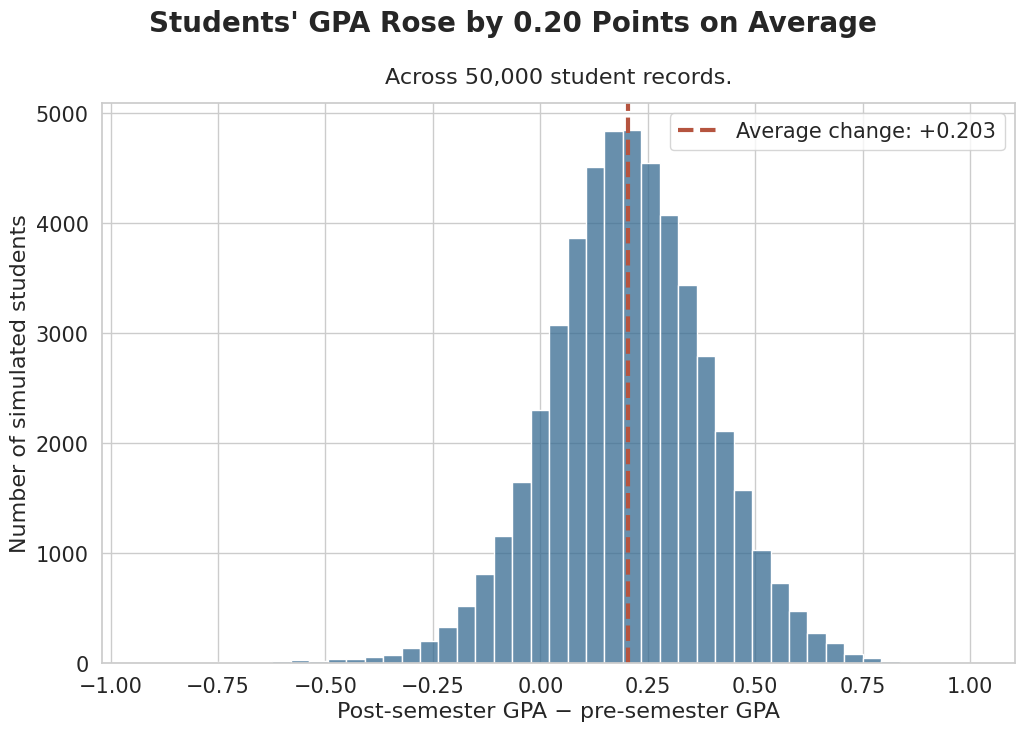

In [ ]:
# Cấu hình đồng bộ kích thước font chữ cực lớn chuyên dụng cho trình chiếu
plt.rcParams.update({
    'font.size': 15,
    'axes.labelsize': 16,
    'axes.titlesize': 16,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15
})

# Figure 1 — how much did GPA change overall?
mean_gain = data["GPA_Change"].mean()
pct_improved = 100 * (data["GPA_Change"] > 0).mean()
fig, ax = plt.subplots(figsize=(10.5, 7.5))
sns.histplot(data["GPA_Change"], bins=45, color="#356a91", ax=ax)
ax.axvline(mean_gain, color="#b5543f", linestyle="--", linewidth=3.0,
           label=f"Average change: {mean_gain:+.3f}")
ax.set_xlabel("Post-semester GPA − pre-semester GPA", fontsize=16)
ax.set_ylabel("Number of simulated students", fontsize=16)
ax.legend(fontsize=15)
fig.suptitle(f"Students' GPA Rose by {mean_gain:.2f} Points on Average", fontsize=20, fontweight='bold')
ax.set_title(f"Across {len(data):,} student records.", fontsize=16, pad=14)
plt.tight_layout()
plt.show()

,AI_Hour_Group,students,mean_gpa_change,mean_retention
0,0–5,22592,0.195,75.980
1,5–10,12173,0.227,77.079
2,10–20,10229,0.216,76.586
3,20–40,5006,0.156,70.252


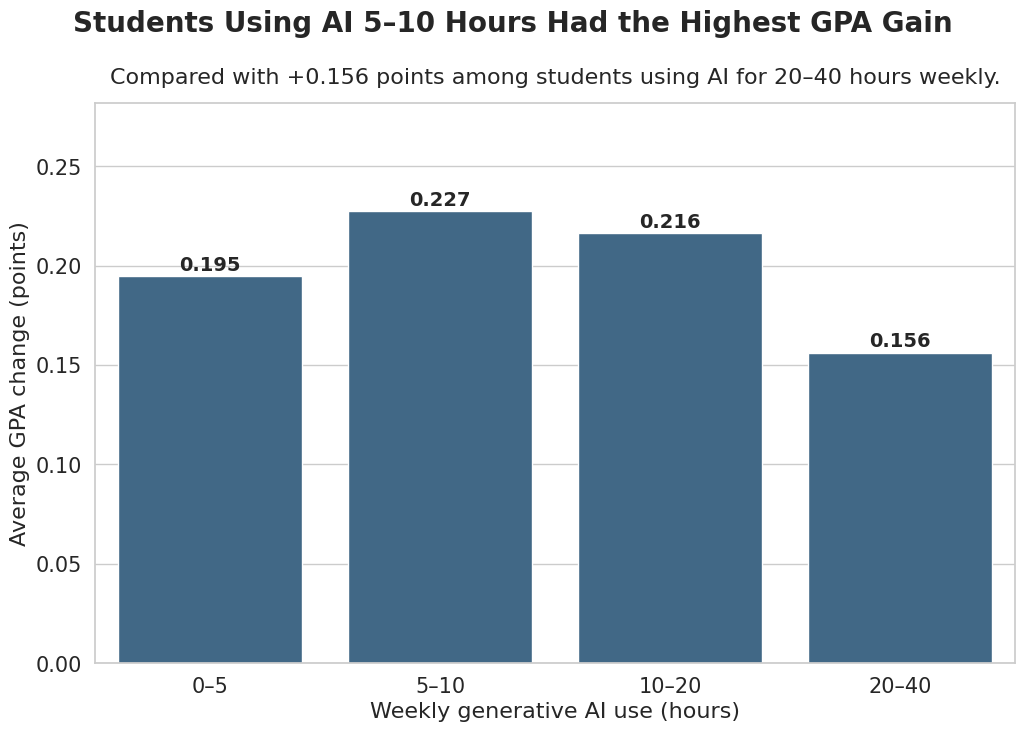

In [ ]:
# Figure 2 — group AI use into ranges that people can compare.
labels = ["0–5", "5–10", "10–20", "20–40"]
data["AI_Hour_Group"] = pd.cut(
    data["Weekly_GenAI_Hours"], bins=[-0.001, 5, 10, 20, 40.001], labels=labels
)
hour_summary = (data.groupby("AI_Hour_Group", observed=True)
                .agg(students=("Student_ID", "size"),
                     mean_gpa_change=("GPA_Change", "mean"),
                     mean_retention=("Skill_Retention_Score", "mean"))
                .reset_index())
display(hour_summary.round(3))
best_ai_group = hour_summary.loc[hour_summary["mean_gpa_change"].idxmax()]
long_hours_group = hour_summary.loc[hour_summary["AI_Hour_Group"] == "20–40"].iloc[0]
fig, ax = plt.subplots(figsize=(10.5, 7.5))
sns.barplot(data=hour_summary, x="AI_Hour_Group", y="mean_gpa_change", color="#356a91", ax=ax)
for i, value in enumerate(hour_summary["mean_gpa_change"]):
    ax.text(i, value + 0.003, f"{value:.3f}", ha="center", fontsize=14, fontweight='bold')
ax.set_ylim(0, hour_summary["mean_gpa_change"].max() * 1.24)
ax.set_xlabel("Weekly generative AI use (hours)", fontsize=16)
ax.set_ylabel("Average GPA change (points)", fontsize=16)
fig.suptitle(f"Students Using AI {best_ai_group['AI_Hour_Group']} Hours Had the Highest GPA Gain", fontsize=20, fontweight='bold')
ax.set_title(f"Compared with +{long_hours_group['mean_gpa_change']:.3f} points among students using AI for 20–40 hours weekly.", fontsize=16, pad=14)
plt.tight_layout()
plt.show()

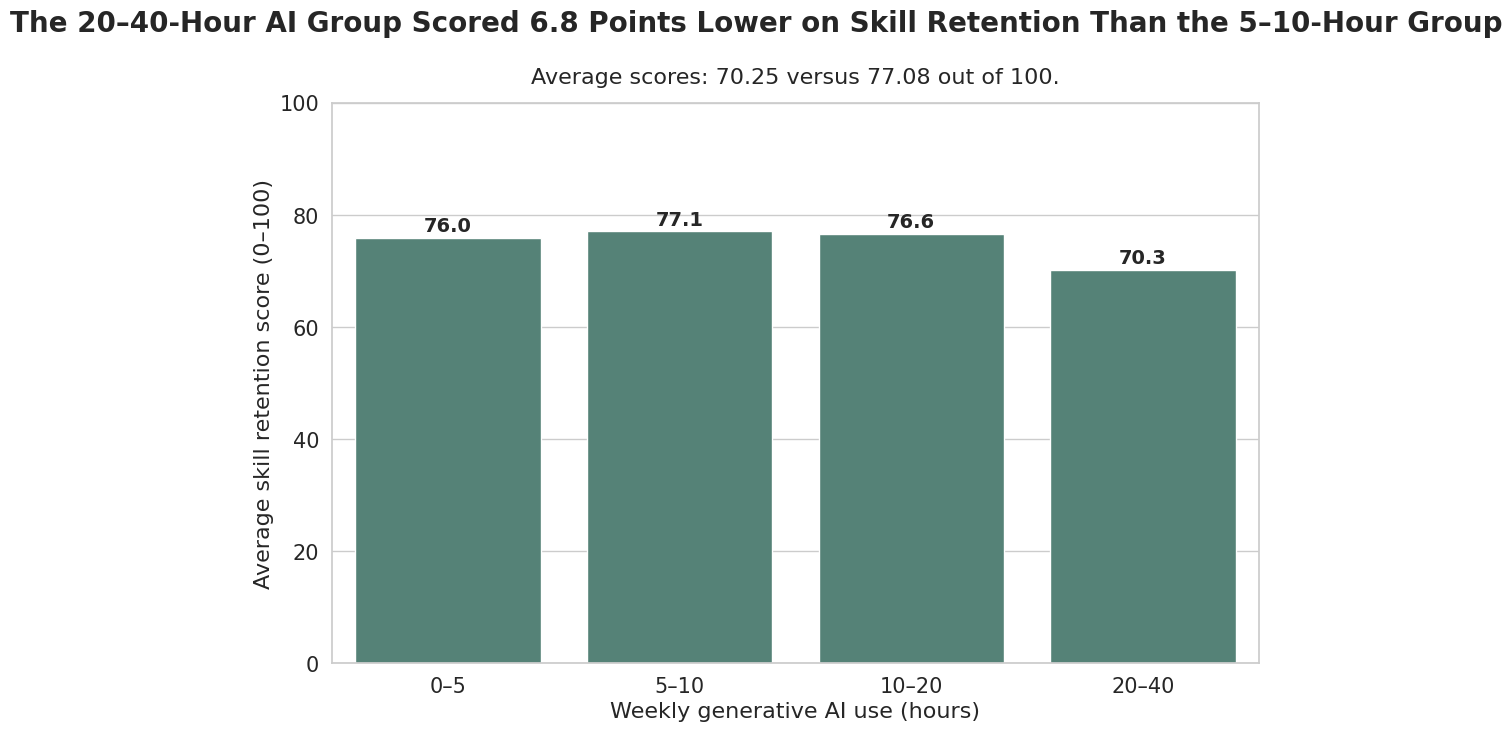

In [ ]:
# Figure 3 — does average skill retention differ between AI-use groups?
low_hours_retention = hour_summary.loc[
    hour_summary["AI_Hour_Group"] == "5–10", "mean_retention"
].iloc[0]
high_hours_retention = hour_summary.loc[
    hour_summary["AI_Hour_Group"] == "20–40", "mean_retention"
].iloc[0]
retention_gap = low_hours_retention - high_hours_retention
fig, ax = plt.subplots(figsize=(10.5, 7.5))
sns.barplot(data=hour_summary, x="AI_Hour_Group", y="mean_retention", color="#4e897b", ax=ax)
for i, value in enumerate(hour_summary["mean_retention"]):
    ax.text(i, value + 1.1, f"{value:.1f}", ha="center", fontsize=14, fontweight='bold')
ax.set_xlabel("Weekly generative AI use (hours)", fontsize=16)
ax.set_ylabel("Average skill retention score (0–100)", fontsize=16)
ax.set_ylim(0, 100)
fig.suptitle(f"The 20–40-Hour AI Group Scored {retention_gap:.1f} Points Lower on Skill Retention Than the 5–10-Hour Group", fontsize=20, fontweight='bold')
ax.set_title(f"Average scores: {high_hours_retention:.2f} versus {low_hours_retention:.2f} out of 100.", fontsize=16, pad=14)
plt.tight_layout()
plt.show()

,Primary_Use_Case,students,mean_gpa_change,mean_retention
2,Direct_Answer_Generation,6340,0.133,73.719
4,Summarizing_Reading,8633,0.197,75.225
3,Ideation,10721,0.200,75.520
0,Copywriting/Drafting,12011,0.200,75.231
1,Debugging/Troubleshooting,12295,0.249,78.069


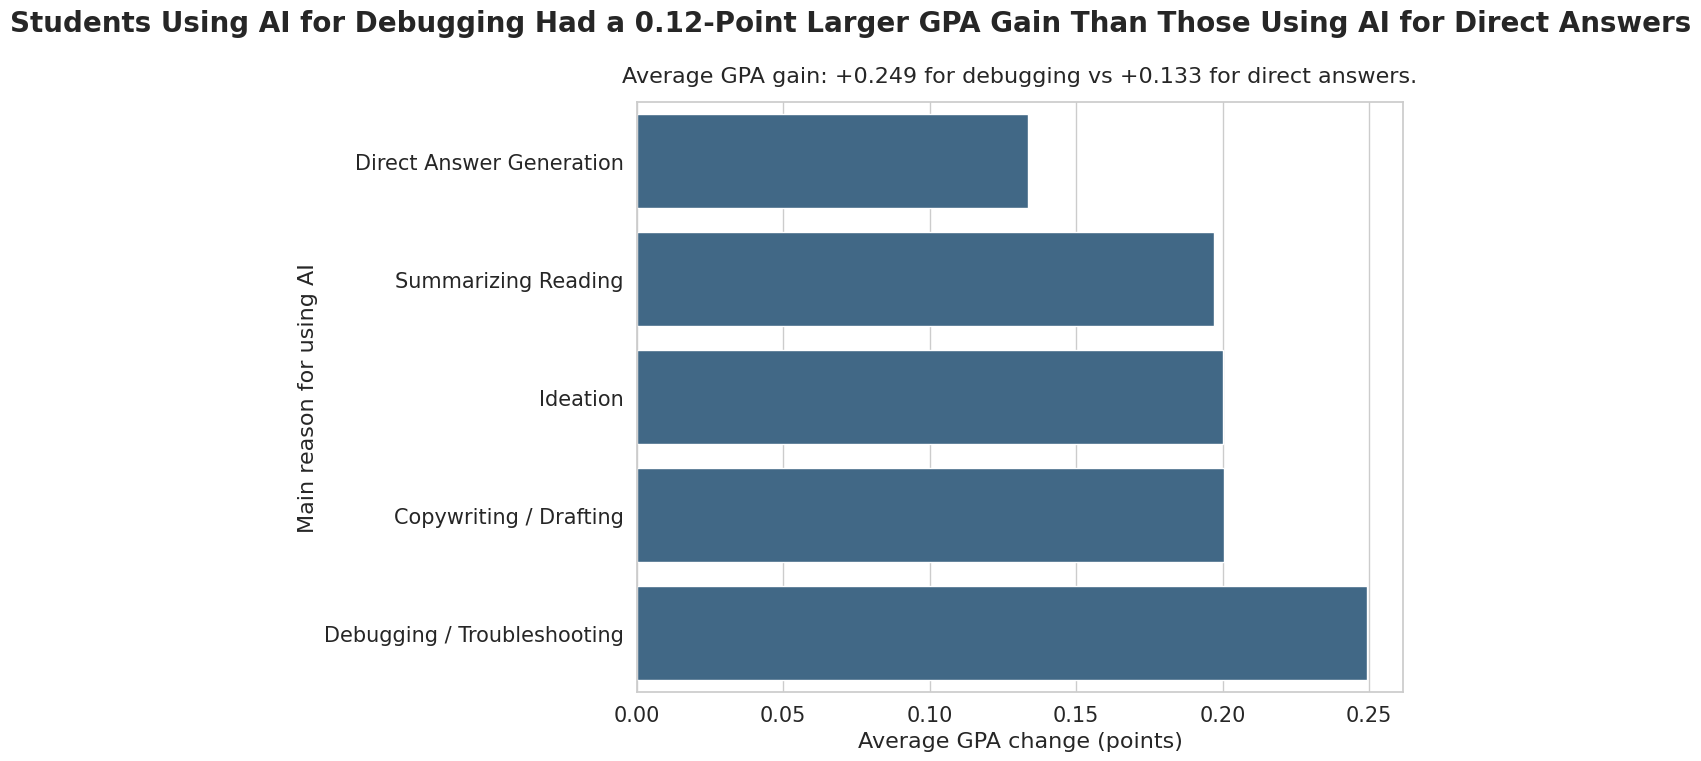

In [ ]:
# Figure 4 — compare the main reasons students use AI.
use_summary = (data.groupby("Primary_Use_Case", as_index=False)
               .agg(students=("Student_ID", "size"),
                    mean_gpa_change=("GPA_Change", "mean"),
                    mean_retention=("Skill_Retention_Score", "mean"))
               .sort_values("mean_gpa_change"))
display(use_summary.round(3))
debugging_gain = use_summary.loc[
    use_summary["Primary_Use_Case"] == "Debugging/Troubleshooting", "mean_gpa_change"
].iloc[0]
direct_answer_gain = use_summary.loc[
    use_summary["Primary_Use_Case"] == "Direct_Answer_Generation", "mean_gpa_change"
].iloc[0]
use_case_gap = debugging_gain - direct_answer_gain
fig, ax = plt.subplots(figsize=(11.5, 7.8))
sns.barplot(data=use_summary, y="Primary_Use_Case", x="mean_gpa_change", color="#356a91", ax=ax)
formatted_labels = [label.replace("_", " ").replace("/", " / ") for label in use_summary["Primary_Use_Case"]]
ax.set_yticks(range(len(formatted_labels)))
ax.set_yticklabels(formatted_labels, fontsize=15)
ax.set_xlabel("Average GPA change (points)", fontsize=16)
ax.set_ylabel("Main reason for using AI", fontsize=16)
fig.suptitle(f"Students Using AI for Debugging Had a {use_case_gap:.2f}-Point Larger GPA Gain Than Those Using AI for Direct Answers", fontsize=20, fontweight='bold')
ax.set_title(f"Average GPA gain: +{debugging_gain:.3f} for debugging vs +{direct_answer_gain:.3f} for direct answers.", fontsize=16, pad=14)
plt.tight_layout()
plt.show()

## 5. Prepare the regression models

I will compare **Multiple Linear Regression** with **Random Forest Regression**. Linear Regression is a transparent baseline for numerical prediction; Random Forest can capture relationships that are not straight lines.

**Prediction target 1:** `GPA_Change`  
**Prediction target 2:** `Skill_Retention_Score` (secondary analysis)

Important decisions:

- Do **not** feed `Student_ID`, `Post_Semester_GPA` or either outcome into the predictor set. `Post_Semester_GPA` would reveal part of the answer when predicting GPA change.
- Do **not** use `Burnout_Risk_Level` as an input: its timing and construction are unclear and it may reflect information from the same period as the outcomes.
- Split students into training and test sets **before fitting imputers or encoders**. Reserve the test set for final evaluation.
- Use one shared 80/20 split for both targets so the model comparisons are consistent.

In [ ]:
# Keep only variables that could reasonably describe a student's AI use,
# study behaviour or background at the time of analysis.
numeric_features = [
    "Pre_Semester_GPA", "Weekly_GenAI_Hours", "Traditional_Study_Hours",
    "Tool_Diversity", "Paid_Subscription", "Perceived_AI_Dependency",
    "Anxiety_Level_During_Exams", "AI_Study_Share"
]
categorical_features = [
    "Major_Category", "Year_of_Study", "Primary_Use_Case",
    "Prompt_Engineering_Skill", "Institutional_Policy"
]
features = numeric_features + categorical_features

X = data[features]
y_gpa = data["GPA_Change"]
y_retention = data["Skill_Retention_Score"]

X_train, X_test, gpa_train, gpa_test, retention_train, retention_test = train_test_split(
    X, y_gpa, y_retention, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Training: {len(X_train):,} rows | Test: {len(X_test):,} rows")
print(f"Predictors: {len(features)} original features")

Training: 40,000 rows | Test: 10,000 rows
Predictors: 13 original features


In [ ]:
# Fit data preparation only on the training set using sklearn pipelines.
# StandardScaler helps the linear model; it does not harm the tree model.
preprocessing = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

def make_model(regressor):
    return Pipeline([("preprocess", preprocessing), ("model", regressor)])


def regression_scores(model_name, model, X_fit, y_fit, X_holdout, y_holdout):
    # Train and test scores help reveal overfitting.
    pred_train = model.predict(X_fit)
    pred_test = model.predict(X_holdout)
    return {
        "model": model_name,
        "train_R2": r2_score(y_fit, pred_train),
        "test_R2": r2_score(y_holdout, pred_test),
        "MAE": mean_absolute_error(y_holdout, pred_test),
        "RMSE": np.sqrt(mean_squared_error(y_holdout, pred_test))
    }

## 6. Small validation experiment: choosing a Random Forest

Rather than immediately selecting the most complex forest, I will try **two reasonable settings** using a validation split taken from the training data. The final test set remains untouched. I will select the setting with the lower validation MAE for **GPA change** and then refit it on the full training data.

This is a modest tuning experiment, not an exhaustive search.

In [ ]:
X_fit, X_val, gpa_fit, gpa_val = train_test_split(
    X_train, gpa_train, test_size=0.20, random_state=RANDOM_STATE
)

forest_options = [
    {"max_depth": 8, "min_samples_leaf": 40},
    {"max_depth": 12, "min_samples_leaf": 20}
]
validation_results = []

for option in forest_options:
    candidate = make_model(RandomForestRegressor(
        n_estimators=60, random_state=RANDOM_STATE, n_jobs=-1, **option
    ))
    candidate.fit(X_fit, gpa_fit)
    prediction = candidate.predict(X_val)
    validation_results.append({**option, "validation_MAE": mean_absolute_error(gpa_val, prediction)})

validation_table = pd.DataFrame(validation_results).sort_values("validation_MAE")
display(validation_table.round(4))
best_option = {k: int(validation_table.iloc[0][k]) for k in ("max_depth", "min_samples_leaf")}
print("Selected forest settings:", best_option)

,max_depth,min_samples_leaf,validation_MAE
1,12,20,0.1156
0,8,40,0.1165


Selected forest settings: {'max_depth': 12, 'min_samples_leaf': 20}


## 7. Model 1: predict GPA change

I will report a simple **mean-prediction baseline** alongside the two required regression approaches. This matters because a model may look impressive while doing little better than predicting the average GPA change for everyone.

In [ ]:
# Fit all models on the full training set, not on the validation subset.
gpa_models = {
    "Mean baseline": make_model(DummyRegressor(strategy="mean")),
    "Multiple Linear Regression": make_model(LinearRegression()),
    "Random Forest Regression": make_model(RandomForestRegressor(
        n_estimators=80, random_state=RANDOM_STATE, n_jobs=-1, **best_option
    ))
}

for model in gpa_models.values():
    model.fit(X_train, gpa_train)

gpa_results = pd.DataFrame([
    regression_scores(name, model, X_train, gpa_train, X_test, gpa_test)
    for name, model in gpa_models.items()
])
display(gpa_results.round(4))

,model,train_R2,test_R2,MAE,RMSE
0,Mean baseline,0.0000,-0.0003,0.1444,0.1854
1,Multiple Linear Regression,0.2743,0.2799,0.1237,0.1573
2,Random Forest Regression,0.4740,0.3979,0.1133,0.1438


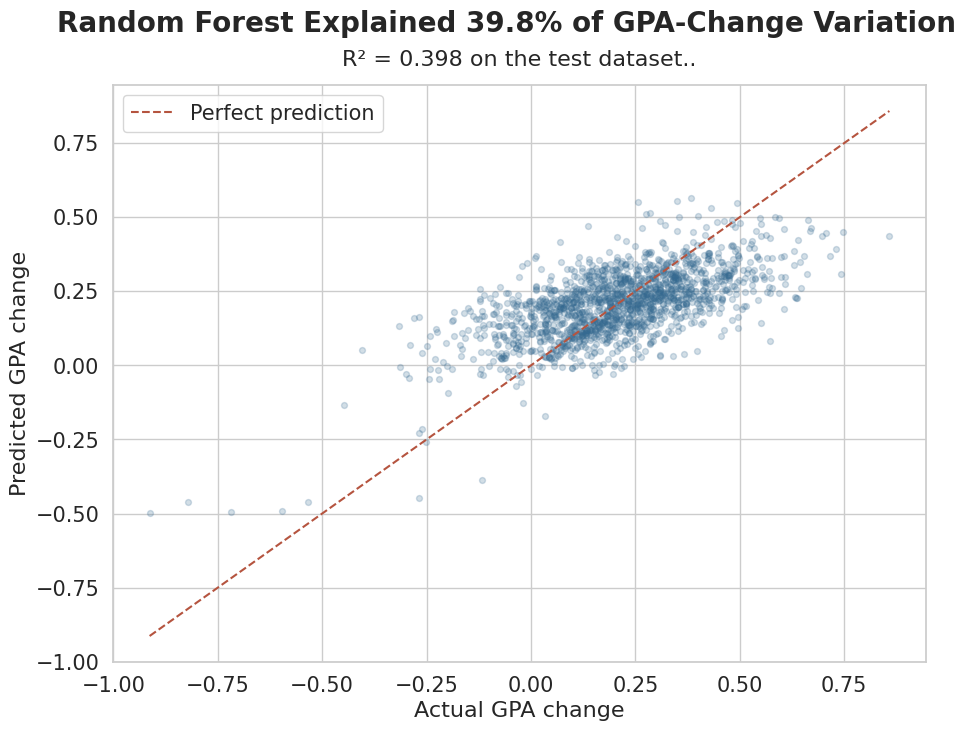

In [ ]:
rf_gpa = gpa_models["Random Forest Regression"]
rf_predictions = rf_gpa.predict(X_test)
rf_test_r2 = r2_score(gpa_test, rf_predictions)
rf_test_mae = mean_absolute_error(gpa_test, rf_predictions)
sample_index = X_test.sample(n=min(1600, len(X_test)), random_state=RANDOM_STATE).index
actual_sample = gpa_test.loc[sample_index]
predicted_sample = pd.Series(rf_predictions, index=X_test.index).loc[sample_index]
fig, ax = plt.subplots(figsize=(10.5, 7.5))
ax.scatter(actual_sample, predicted_sample, alpha=0.22, s=18, color="#356a91")
limits = [min(actual_sample.min(), predicted_sample.min()),
          max(actual_sample.max(), predicted_sample.max())]
ax.plot(limits, limits, "--", color="#b5543f", label="Perfect prediction")
ax.set_xlabel("Actual GPA change", fontsize=16)
ax.set_ylabel("Predicted GPA change", fontsize=16)
ax.legend(fontsize=15)
fig.suptitle(f"Random Forest Explained {rf_test_r2 * 100:.1f}% of GPA-Change Variation", fontsize=20, fontweight='bold')
ax.set_title(f"R² = {rf_test_r2:.3f} on the test dataset..", fontsize=16, pad=14)
plt.show()

## 8. Model 2: predict skill retention

Now I will repeat the comparison with the **skill retention score**. I will use the same original predictors and the forest settings selected for GPA change. This keeps the secondary analysis manageable, although a separate tuning exercise could improve its results.

In [ ]:
retention_models = {
    "Mean baseline": make_model(DummyRegressor(strategy="mean")),
    "Multiple Linear Regression": make_model(LinearRegression()),
    "Random Forest Regression": make_model(RandomForestRegressor(
        n_estimators=80, random_state=RANDOM_STATE, n_jobs=-1, **best_option
    ))
}

for model in retention_models.values():
    model.fit(X_train, retention_train)

retention_results = pd.DataFrame([
    regression_scores(name, model, X_train, retention_train, X_test, retention_test)
    for name, model in retention_models.items()
])
display(retention_results.round(4))

print("MAE measures GPA points in the first task and retention-score points in the second.")
print("Do not compare MAE values across different outcome scales directly.")

,model,train_R2,test_R2,MAE,RMSE
0,Mean baseline,0.0000,-0.000,10.7371,13.2769
1,Multiple Linear Regression,0.1822,0.182,9.7035,12.0081
2,Random Forest Regression,0.3083,0.212,9.5224,11.7855


MAE measures GPA points in the first task and retention-score points in the second.
Do not compare MAE values across different outcome scales directly.


## 9. Which inputs matter to GPA-change predictions?

Model scores tell me **how well** the forest predicts. I also want to know **which inputs it relies on**. I will use permutation importance on a small, held-out sample: each variable is shuffled, and the decline in test R² is measured.

This is **predictive importance**, not proof that changing the input would change the student's grades.

,feature,mean_R2_drop,std
2,Traditional_Study_Hours,0.3265,0.0107
10,Primary_Use_Case,0.2458,0.0168
9,Year_of_Study,0.1198,0.0016
0,Pre_Semester_GPA,0.1188,0.0118
1,Weekly_GenAI_Hours,0.1013,0.0074
11,Prompt_Engineering_Skill,0.0952,0.0050
12,Institutional_Policy,0.0074,0.0015
7,AI_Study_Share,0.0071,0.0008
4,Paid_Subscription,0.0031,0.0017
6,Anxiety_Level_During_Exams,0.0001,0.0008


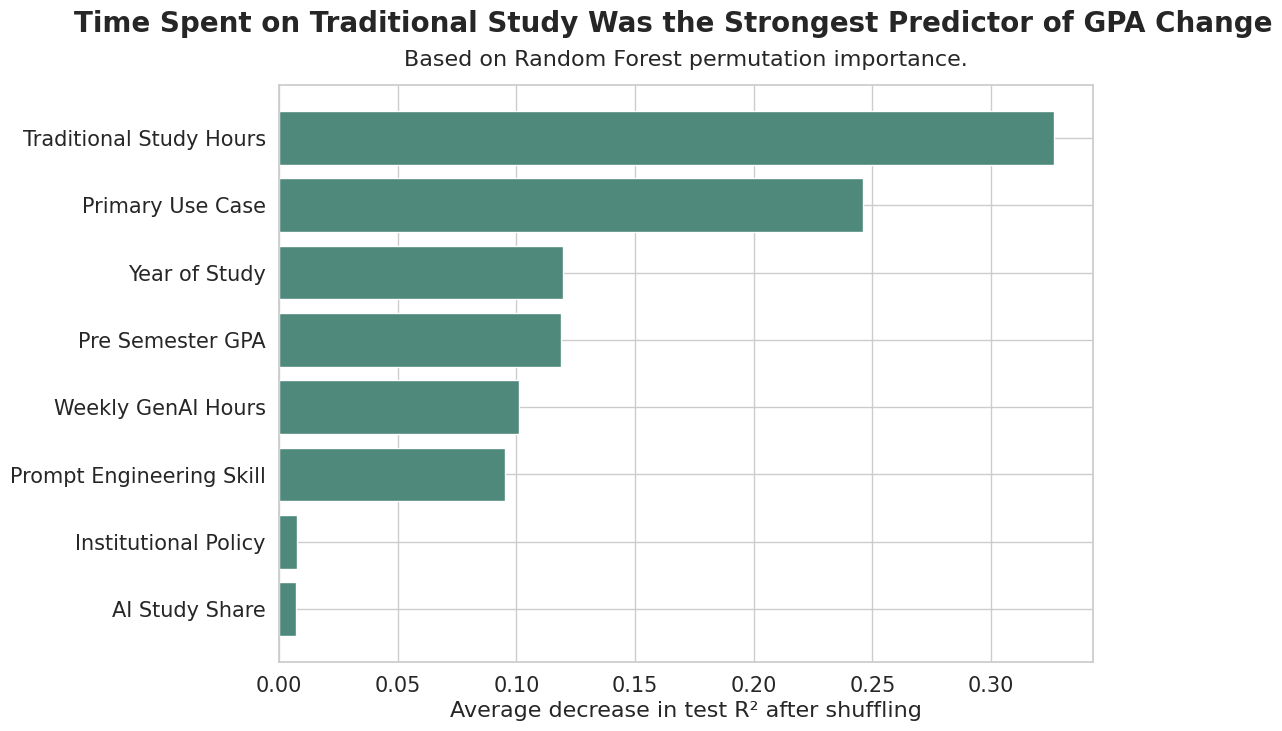

In [ ]:
importance_index = X_test.sample(n=min(2000, len(X_test)), random_state=RANDOM_STATE).index
importance = permutation_importance(
    rf_gpa, X_test.loc[importance_index], gpa_test.loc[importance_index],
    n_repeats=3, random_state=RANDOM_STATE, scoring="r2", n_jobs=1
)
importance_table = (pd.DataFrame({
    "feature": features,
    "mean_R2_drop": importance.importances_mean,
    "std": importance.importances_std
}).sort_values("mean_R2_drop", ascending=False))
display(importance_table.head(10).round(4))
plot_data = importance_table.head(8).sort_values("mean_R2_drop").copy()
plot_data["readable_feature"] = plot_data["feature"].str.replace("_", " ", regex=False)
top_predictor = importance_table.iloc[0]
top_predictor_label = ("Time Spent on Traditional Study" if top_predictor["feature"] == "Traditional_Study_Hours"
                       else top_predictor["feature"].replace("_", " "))
fig, ax = plt.subplots(figsize=(10.5, 7.5))
ax.barh(plot_data["readable_feature"], plot_data["mean_R2_drop"], color="#4e897b")
ax.set_xlabel("Average decrease in test R² after shuffling", fontsize=16)
ax.tick_params(axis='y', labelsize=15)
fig.suptitle(f"{top_predictor_label} Was the Strongest Predictor of GPA Change", fontsize=20, fontweight='bold')
ax.set_title(f"Based on Random Forest permutation importance.", fontsize=16, pad=14)
plt.show()